# pyhf expected-significance cross-check for H&rarr;&mu;&mu;

This notebook is a **step-by-step, binned likelihood-fit cross-check** of the
H&rarr;&mu;&mu; expected discovery significance that the analysis normally gets from
`flashggFinalFit` + Combine (parametric unbinned fits, `RooMultiPdf` background
envelope with discrete profiling, `combine -M Significance -t -1 --expectSignal 1`).

**Why pyhf?** It is a transparent, pure-Python implementation of the HistFactory
binned-template likelihood. It *cannot* reproduce discrete profiling or unbinned
parametric PDFs, so this is a **sanity check on the order of magnitude and the
per-category breakdown**, not a replacement for Combine.

### What we do
1. Load the BDT-category-split tuples (`root_io/tuples/split_tuples/`).
2. Fit a **parametric signal peak** (double Crystal Ball) per category.
3. Build **two background models** and compare:
   * **A** &mdash; analytic fit to the **data sidebands** (110&ndash;120 &amp; 130&ndash;150 GeV),
     evaluated through the blind window. Closest in spirit to the Combine bump hunt.
   * **B** &mdash; **MC templates** (DY/EWK/TT/DiBoson).
4. Assemble a **pyhf workspace**: one channel per category, signal + background
   samples, signal systematics + floating background.
5. Build the **Asimov dataset** ( `b + s(&mu;=1)` ) and compute the discovery
   test statistic **q0**; the expected significance is `Z = sqrt(q0)`.
6. Per-category + combined significance, plus diagnostics.

### Blinding
Real data with dimuon mass in **120&ndash;130 GeV** is never read: `fit_inputs.load_signal`
drops it before returning anything. The Asimov dataset uses the *sideband-fitted*
background through the blind window plus MC signal &mdash; no blinded data is needed.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # numpy 'subnormal' spam on this platform

import sys, os
# run from the repo root so `python.fits` imports resolve
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if os.path.basename(REPO) != "HToMuMu":
    REPO = "/uscms_data/d3/esledge/CMSSW_14_0_14/src/HToMuMu"
os.chdir(REPO); sys.path.insert(0, REPO)

import numpy as np
import matplotlib.pyplot as plt
import pyhf

from python.fits import fit_config as cfg
from python.fits import fit_inputs, signal_model, background_model, workspace, significance
from python.fits import plotting

pyhf.set_backend(*cfg.PYHF_BACKEND)
EDGES = cfg.mass_bins()
CENTERS = 0.5 * (EDGES[1:] + EDGES[:-1])
CATS = cfg.resolve_categories("all")   # discovered from the ROOT files
print("categories:", CATS)
print("pyhf", pyhf.__version__, "| backend", pyhf.tensorlib.name)
print("mass range", cfg.FIT_RANGE, "| bin width", cfg.BIN_WIDTH, "GeV |", len(CENTERS), "bins")
print("blind window", cfg.BLIND_WINDOW, "| lumi", cfg.LUMI_FB, "fb^-1 | BR(H->mumu)", cfg.BR_HMM)

categories: ['ggHcat1', 'ggHcat2', 'ggHcat3', 'ggHcat4', 'ggHcat5', 'VBFcat1', 'VBFcat2', 'VBFcat3', 'VBFcat4', 'VBFcat5', 'VBFcat6']
pyhf 0.7.6 | backend numpy
mass range (110.0, 150.0) | bin width 0.5 GeV | 80 bins
blind window (120.0, 130.0) | lumi 281.7 fb^-1 | BR(H->mumu) 0.0002176


## Step 1 &mdash; Load inputs

`load_signal` returns one `CategoryInputs` per category with the weighted ggH and
VBF signal MC and the **already-blinded** data. Physical signal yield at &mu;=1 is
`sum(weight) * BR` &mdash; the split trees have the branching ratio divided back out
(`scripts/split_tuples.py`).

The tuples correspond to the full 2022&ndash;2025 dataset (~281.7 fb⁻¹).

In [2]:
inputs = fit_inputs.load_signal(CATS)
print(fit_inputs.summary_table(inputs))

category       S_ggH     S_VBF     S_tot    S(win)    data_SB
ggHcat1        13.41      7.10     20.51     16.16       2279
ggHcat2        69.10     19.64     88.74     70.55      20302
ggHcat3       394.75     41.33    436.08    351.05     232897
ggHcat4       802.94     27.75    830.69    648.02     829225
ggHcat5       522.85      6.48    529.33    393.97    1377323
VBFcat1         0.03      1.20      1.23      0.98         14
VBFcat2         0.38      5.36      5.74      4.53        101
VBFcat3         1.01      6.16      7.17      5.53        291
VBFcat4         5.60     11.96     17.56     13.57       1952
VBFcat5         7.50      8.73     16.23     12.35       4469
VBFcat6         7.26      6.71     13.97     10.24      16986


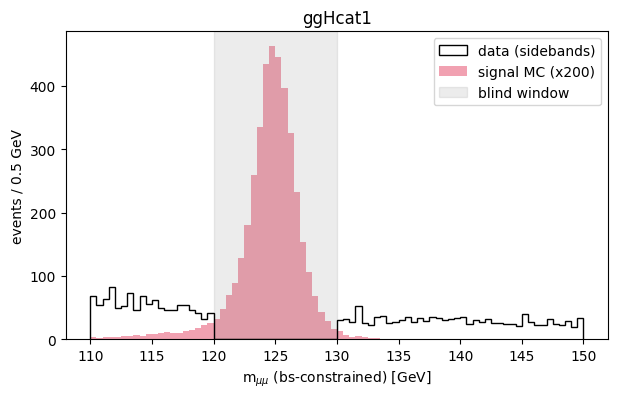

In [3]:
# Look at one category: signal MC shape vs (blinded) data sidebands
ci = inputs["ggHcat1"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ci.data_mass_blinded, bins=EDGES, histtype="step", color="k", label="data (sidebands)")
w = np.concatenate([ci.sig_ggh_w, ci.sig_vbf_w]) * cfg.BR_HMM
m = np.concatenate([ci.sig_ggh_mass, ci.sig_vbf_mass])
ax.hist(m, bins=EDGES, weights=w * 200, histtype="stepfilled", alpha=.4,
        color="crimson", label="signal MC (x200)")
ax.axvspan(*cfg.BLIND_WINDOW, color="grey", alpha=.15, label="blind window")
ax.set_xlabel("m$_{\\mu\\mu}$ (bs-constrained) [GeV]"); ax.set_ylabel("events / 0.5 GeV")
ax.set_title("ggHcat1"); ax.legend(); plt.show()

## Step 2 &mdash; Parametric signal model

For each category we fit a **double-sided Crystal Ball** (Gaussian core + power-law
tails) to the weighted ggH+VBF signal MC. The fitted shape is sampled into the
analysis bins and scaled to the &mu;=1 yield. Two shape systematics are derived:

* **MassScale** &mdash; peak mean shifted by &plusmn;0.2%
* **MassReso**  &mdash; width scaled by 1 &plusmn; 10%

family=dscb  mean=124.901 GeV  sigma_eff=1.857 GeV
yield: ggH=69.10  VBF=19.64  total=88.74


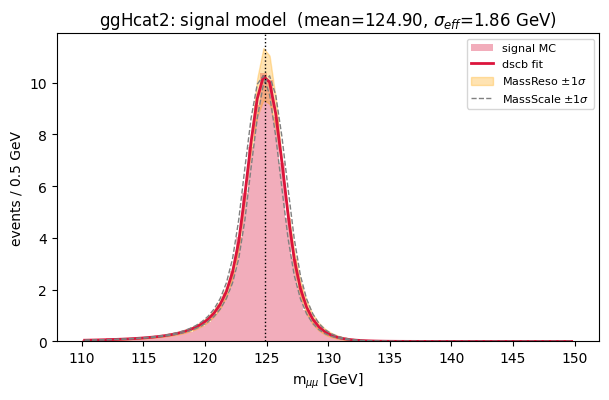

In [4]:
sh = signal_model.fit_signal(inputs["ggHcat2"], edges=EDGES, verbose=True)
print(f"family={sh.family}  mean={sh.mean:.3f} GeV  sigma_eff={sh.sigma_eff:.3f} GeV")
print(f"yield: ggH={sh.yield_ggh:.2f}  VBF={sh.yield_vbf:.2f}  total={sh.yield_total:.2f}")
plotting.plot_signal_fit(inputs["ggHcat2"], sh, EDGES); plt.show()

In [5]:
signals = signal_model.fit_all_signals(inputs, edges=EDGES)
print(f"{'cat':10s} {'family':10s} {'mean':>8s} {'sig_eff':>8s} {'yield':>9s} {'chi2/ndf':>9s}")
for c, s in signals.items():
    print(f"{c:10s} {s.family:10s} {s.mean:8.3f} {s.sigma_eff:8.3f} {s.yield_total:9.2f} {s.chi2ndf:9.2f}")

cat        family         mean  sig_eff     yield  chi2/ndf
ggHcat1    dscb        124.922    1.892     20.51      0.03
ggHcat2    dscb        124.901    1.857     88.74      0.01
ggHcat3    dscb        124.902    1.795    436.08      0.01
ggHcat4    dscb        124.849    1.935    830.69      0.01
ggHcat5    dscb        124.805    2.158    529.33      0.01
VBFcat1    dscb        124.914    1.864      1.23      0.03
VBFcat2    dscb        124.856    1.909      5.74      0.02
VBFcat3    dscb        124.850    1.982      7.17      0.03
VBFcat4    dscb        124.856    1.976     17.56      0.02
VBFcat5    dscb        124.845    2.053     16.23      0.03
VBFcat6    dscb        124.827    2.219     13.97      0.04


## Step 3 &mdash; Background model A: analytic fit to the data sidebands

We fit a family of smooth functions (exponentials, power law, Bernstein
polynomials 3&ndash;5) to the **sideband** bin counts only, pick the best by AIC, and
evaluate it across the full range &mdash; **interpolating through the blind window
using sideband information only**.

The fit covariance is eigen-decomposed into a few **shape nuisance parameters**
(Gaussian-constrained `histosys`). The overall background level is a **free,
unconstrained** normalisation (`bkg_norm_<cat>`) added in the workspace.

  [ggHcat2] exp    chi2/ndf= 1.41 AIC=    85.6
  [ggHcat2] exp2   chi2/ndf= 0.88 AIC=    57.5
  [ggHcat2] pow    chi2/ndf= 1.13 AIC=    69.5
  [ggHcat2] bern3  chi2/ndf= 0.83 AIC=    54.7
  [ggHcat2] bern4  chi2/ndf= 0.85 AIC=    56.6
  [ggHcat2] bern5  chi2/ndf= 0.80 AIC=    55.2
chosen family: bern3  chi2/ndf = 0.83
AIC per family: {'exp': 85.6, 'exp2': 57.5, 'pow': 69.5, 'bern3': 54.7, 'bern4': 56.6, 'bern5': 55.2}


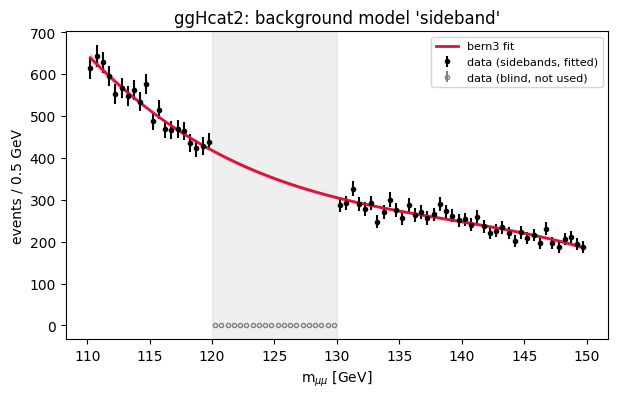

In [6]:
bm = background_model.fit_sideband_background(inputs["ggHcat2"], edges=EDGES, verbose=True)
print("chosen family:", bm.info["family"], " chi2/ndf =", round(bm.info["chi2ndf"], 2))
print("AIC per family:", {k: round(v, 1) for k, v in bm.info["all_families"].items()})
plotting.plot_background_fit(inputs["ggHcat2"], bm, EDGES); plt.show()

In [7]:
# Envelope study: how much does the background function choice move the answer?
fam_models = background_model.fit_sideband_all_families(inputs["ggHcat2"], edges=EDGES)
sh2 = signals["ggHcat2"]
for fam, m_ in fam_models.items():
    spec1 = workspace.build_spec({"ggHcat2": sh2}, {"ggHcat2": m_}, categories=["ggHcat2"])
    mod, dat = workspace.build_model_and_data(spec1, categories=["ggHcat2"])
    z = significance.discovery_significance(mod)["Z"]
    print(f"  {fam:6s}  chi2/ndf={m_.info['chi2ndf']:.2f}   Z(ggHcat2) = {z:.3f}")

  exp     chi2/ndf=1.41   Z(ggHcat2) = 1.108
  exp2    chi2/ndf=0.88   Z(ggHcat2) = 1.049
  pow     chi2/ndf=1.13   Z(ggHcat2) = 1.120


  bern3   chi2/ndf=0.83   Z(ggHcat2) = 1.021
  bern4   chi2/ndf=0.85   Z(ggHcat2) = 1.036
  bern5   chi2/ndf=0.80   Z(ggHcat2) = 0.923


In [8]:
backgrounds_sb = {c: background_model.fit_sideband_background(inputs[c], edges=EDGES)
                  for c in CATS}
for c, b in backgrounds_sb.items():
    print(f"{c:10s} family={b.info['family']:6s} chi2/ndf={b.info['chi2ndf']:5.2f} "
          f"B={b.yield_total:12.1f}")

ggHcat1    family=bern3  chi2/ndf= 1.15 B=      2939.6
ggHcat2    family=bern3  chi2/ndf= 0.83 B=     27341.4
ggHcat3    family=bern4  chi2/ndf= 1.37 B=    316784.9
ggHcat4    family=exp2   chi2/ndf= 1.79 B=   1121626.1
ggHcat5    family=exp2   chi2/ndf= 2.75 B=   1817637.7
VBFcat1    family=pow    chi2/ndf= 0.00 B=        80.0
VBFcat2    family=pow    chi2/ndf= 0.46 B=       115.1
VBFcat3    family=exp    chi2/ndf= 1.10 B=       313.5
VBFcat4    family=pow    chi2/ndf= 1.17 B=      2588.6
VBFcat5    family=bern4  chi2/ndf= 0.88 B=      6003.1
VBFcat6    family=exp2   chi2/ndf= 0.94 B=     22671.6


## Step 4 &mdash; Background model B: MC templates

DY + EWK + TT + DiBoson, re-cut with the same BDT-score / category selection as
`scripts/split_tuples.py`. Modifiers: free `bkg_norm` plus a linear-tilt and a
quadratic-curvature shape nuisance (per-bin `staterror` would be one gamma per
bin &mdash; far too slow for the combined fit; MC-stat is not fully captured in
model B, which is fine since model A is the real cross-check).

> This reads the multi-GB upstream tuples (`root_io/tuples/BDT_score/`). The DY
> file alone is ~3.7 GB &mdash; expect a minute or two.

In [9]:
fit_inputs.load_mc_background(inputs)          # fills ci.bkg_mass / ci.bkg_w
backgrounds_mc = {c: background_model.mc_template_background(inputs[c], edges=EDGES)
                  for c in CATS}
for c, b in backgrounds_mc.items():
    print(f"{c:10s} B={b.yield_total:12.1f}  (MC entries {b.info['mc_entries']:>8d})")

ggHcat1    B=      2283.4  (MC entries    34564)
ggHcat2    B=     22774.6  (MC entries   289588)
ggHcat3    B=    294717.9  (MC entries  3316730)
ggHcat4    B=   1160046.1  (MC entries  9119053)
ggHcat5    B=   1999328.9  (MC entries 11531853)
VBFcat1    B=         9.1  (MC entries      368)
VBFcat2    B=        99.7  (MC entries     2709)
VBFcat3    B=       190.8  (MC entries     4864)
VBFcat4    B=      1336.2  (MC entries    24548)
VBFcat5    B=      3741.0  (MC entries    57922)
VBFcat6    B=     14624.9  (MC entries   317278)


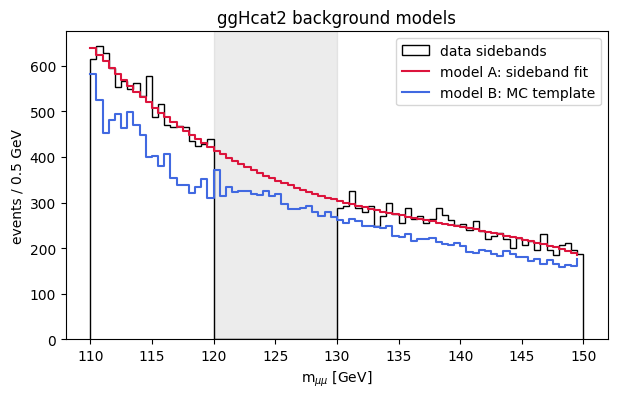

In [10]:
# Sideband fit vs MC template, one category
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(inputs["ggHcat2"].data_mass_blinded, bins=EDGES, histtype="step", color="k",
        label="data sidebands")
ax.step(EDGES[:-1], backgrounds_sb["ggHcat2"].nominal, where="post", color="crimson",
        label="model A: sideband fit")
ax.step(EDGES[:-1], backgrounds_mc["ggHcat2"].nominal, where="post", color="royalblue",
        label="model B: MC template")
ax.axvspan(*cfg.BLIND_WINDOW, color="grey", alpha=.15)
ax.set_xlabel("m$_{\\mu\\mu}$ [GeV]"); ax.set_ylabel("events / 0.5 GeV")
ax.set_title("ggHcat2 background models"); ax.legend(); plt.show()

## Step 5 &mdash; Systematics

Signal normalisation systematics (`fit_config.SIGNAL_NORMSYS` /
`SIGNAL_XS_NORMSYS`) are flat lnN placeholders &mdash; **replace with real numbers**
from the systematic weight branches once `scripts/split_tuples.py` is extended to
carry them (see README). Shape systematics `MassScale` / `MassReso` come from the
signal fit. The background floats (normalisation unconstrained + shape nuisances),
which is what actually drives a bump-hunt result.

In [11]:
import pprint
pprint.pp(dict(cfg.SIGNAL_NORMSYS))
pprint.pp(dict(cfg.SIGNAL_XS_NORMSYS))
print("MASS_SCALE_REL", cfg.MASS_SCALE_REL, " MASS_RESO_REL", cfg.MASS_RESO_REL)

{'lumi_run3': (0.986, 1.014),
 'br_hmm': (0.99, 1.01),
 'muon_sf': (0.98, 1.02),
 'pileup': (0.99, 1.01)}
{'sig_ggH': ('xs_ggH', (0.961, 1.039)), 'sig_VBF': ('xs_VBF', (0.997, 1.004))}
MASS_SCALE_REL 0.002  MASS_RESO_REL 0.1


## Step 6 &mdash; Build the pyhf workspace

One channel per category. Look at the JSON for a single channel to see the
HistFactory structure: two signal samples sharing the POI `mu`, one background
sample with a free `normfactor` and shape `histosys` modifiers.

In [12]:
spec_sb = workspace.build_spec(signals, backgrounds_sb, categories=CATS)
spec_mc = workspace.build_spec(signals, backgrounds_mc, categories=CATS)

import json
ch = [c for c in spec_sb["channels"] if c["name"] == "ggHcat1"][0]
print(json.dumps({"name": ch["name"],
                  "samples": [{"name": s["name"],
                               "modifiers": [m["name"] + ":" + m["type"] for m in s["modifiers"]]}
                              for s in ch["samples"]]}, indent=2))

model_sb, data_sb = workspace.build_model_and_data(spec_sb)
print("\nparameters:", model_sb.config.par_names)
print("POI:", model_sb.config.poi_name)

{
  "name": "ggHcat1",
  "samples": [
    {
      "name": "sig_ggH",
      "modifiers": [
        "mu:normfactor",
        "lumi_run3:normsys",
        "br_hmm:normsys",
        "muon_sf:normsys",
        "pileup:normsys",
        "xs_ggH:normsys",
        "MassScale:histosys",
        "MassReso:histosys"
      ]
    },
    {
      "name": "sig_VBF",
      "modifiers": [
        "mu:normfactor",
        "lumi_run3:normsys",
        "br_hmm:normsys",
        "muon_sf:normsys",
        "pileup:normsys",
        "xs_VBF:normsys",
        "MassScale:histosys",
        "MassReso:histosys"
      ]
    },
    {
      "name": "background",
      "modifiers": [
        "bkg_norm_ggHcat1:normfactor",
        "bkgshape_ggHcat1_0:histosys",
        "bkgshape_ggHcat1_1:histosys",
        "bkgshape_ggHcat1_2:histosys"
      ]
    }
  ]
}



parameters: ['bkgshape_VBFcat1_0', 'bkgshape_VBFcat1_1', 'MassReso', 'MassScale', 'bkgshape_VBFcat2_0', 'bkgshape_VBFcat2_1', 'bkgshape_VBFcat3_0', 'bkgshape_VBFcat3_1', 'bkgshape_VBFcat4_0', 'bkgshape_VBFcat4_1', 'bkgshape_VBFcat5_0', 'bkgshape_VBFcat5_1', 'bkgshape_VBFcat5_2', 'bkgshape_VBFcat6_0', 'bkgshape_VBFcat6_1', 'bkgshape_VBFcat6_2', 'bkgshape_ggHcat1_0', 'bkgshape_ggHcat1_1', 'bkgshape_ggHcat1_2', 'bkgshape_ggHcat2_0', 'bkgshape_ggHcat2_1', 'bkgshape_ggHcat2_2', 'bkgshape_ggHcat3_0', 'bkgshape_ggHcat3_1', 'bkgshape_ggHcat3_2', 'bkgshape_ggHcat4_0', 'bkgshape_ggHcat4_1', 'bkgshape_ggHcat4_2', 'bkgshape_ggHcat5_0', 'bkgshape_ggHcat5_1', 'bkgshape_ggHcat5_2', 'bkg_norm_VBFcat1', 'mu', 'bkg_norm_VBFcat2', 'bkg_norm_VBFcat3', 'bkg_norm_VBFcat4', 'bkg_norm_VBFcat5', 'bkg_norm_VBFcat6', 'bkg_norm_ggHcat1', 'bkg_norm_ggHcat2', 'bkg_norm_ggHcat3', 'bkg_norm_ggHcat4', 'bkg_norm_ggHcat5', 'br_hmm', 'lumi_run3', 'muon_sf', 'pileup', 'xs_VBF', 'xs_ggH']
POI: mu


## Step 7 &mdash; Asimov dataset and the discovery test statistic q0

The **Asimov dataset** replaces the observed data with its expectation. For the
*expected* discovery significance we set the signal to its nominal strength
(&mu; = 1) and all nuisance parameters to nominal:  `d_i = b_i + s_i`.

The discovery test statistic (Cowan et al. 2011, eq. 12) is

$$ q_0 = \begin{cases} 0 & \hat\mu < 0 \\
-2\ln\dfrac{L(0,\hat{\hat\theta})}{L(\hat\mu,\hat\theta)} & \hat\mu \ge 0\end{cases} $$

and in the asymptotic limit the median expected significance is
$Z = \sqrt{q_0}$, $p_0 = 1-\Phi(Z)$. This is the direct analogue of
`combine -M Significance -t -1 --expectSignal 1`.

In [13]:
# one category, by hand
mod, _ = workspace.build_model_and_data(spec_sb, categories=["ggHcat2"])
asimov = significance.make_asimov(mod, mu=1.0)
init, bounds, fixed = mod.config.suggested_init(), mod.config.suggested_bounds(), mod.config.suggested_fixed()

q0 = float(pyhf.infer.test_statistics.q0(0.0, asimov, mod, init, bounds, fixed))
print(f"ggHcat2:  q0 = {q0:.3f}   ->   Z = sqrt(q0) = {q0**0.5:.3f}")

# closure: unconditional fit on the mu=1 Asimov should give mu_hat ~ 1
bestfit = pyhf.infer.mle.fit(asimov, mod)
print("mu_hat =", round(float(bestfit[mod.config.poi_index]), 4),
      " (nuisance pulls should be ~0):",
      np.round(np.delete(np.asarray(bestfit), mod.config.poi_index), 3))

ggHcat2:  q0 = 1.043   ->   Z = sqrt(q0) = 1.021
mu_hat = 1.0  (nuisance pulls should be ~0): [-0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.]


## Step 8 &mdash; Per-category and combined expected significance

`significance_table` builds a single-channel sub-model for each category and the
full 11-channel model, and returns q0 / Z for each.

In [14]:
import pandas as pd
rows_sb = significance.significance_table(spec_sb, edges=EDGES)
rows_mc = significance.significance_table(spec_mc, edges=EDGES)

df = pd.DataFrame(rows_sb)[["category", "s", "b", "s_over_sqrtb", "Z"]].rename(
    columns={"Z": "Z_sideband"})
df["Z_mctemplate"] = pd.DataFrame(rows_mc)["Z"]
df.round({"s": 1, "b": 1, "s_over_sqrtb": 2, "Z_sideband": 3, "Z_mctemplate": 3})

,category,s,b,s_over_sqrtb,Z_sideband,Z_mctemplate
0,ggHcat1,16.2,358.9,0.86,0.721,0.833
1,ggHcat2,70.7,3516.1,1.19,1.021,1.102
2,ggHcat3,351.9,41748.2,1.72,1.520,1.544
3,ggHcat4,649.3,144612.3,1.71,1.511,1.440
4,ggHcat5,394.9,215979.2,0.85,0.745,0.681
5,VBFcat1,1.0,10.0,0.31,0.293,1.183
6,VBFcat2,4.5,15.1,1.17,1.060,1.211
7,VBFcat3,5.5,42.9,0.85,0.795,1.022
8,VBFcat4,13.6,350.4,0.73,0.698,0.874
9,VBFcat5,12.4,785.9,0.44,0.376,0.477


In [15]:
zc_sb = [r for r in rows_sb if r["category"] == "combined"][0]["Z"]
zc_mc = [r for r in rows_mc if r["category"] == "combined"][0]["Z"]
print(f"Combined expected significance (Asimov, mu=1):")
print(f"   background model A (sideband fit)  :  Z = {zc_sb:.2f} sigma")
print(f"   background model B (MC template)   :  Z = {zc_mc:.2f} sigma")
print()
print("Combine reference (Tutorials/...Combine Sig and Impact.md):")
print("   Run3 ggH       ~ 2.33     Run3 VBF ~ 2.08     Run3 ggH+VBF ~ 3.12   (2022-2024 data)")
print("   ~4.8 sigma with 2025 data added (lumi-map 234.35).")
print()
print("These tuples are the 2022-2025 set (~281.7 fb^-1).")

Combined expected significance (Asimov, mu=1):
   background model A (sideband fit)  :  Z = 3.04 sigma
   background model B (MC template)   :  Z = 3.43 sigma

Combine reference (Tutorials/...Combine Sig and Impact.md):
   Run3 ggH       ~ 2.33     Run3 VBF ~ 2.08     Run3 ggH+VBF ~ 3.12   (2022-2024 data)
   ~4.8 sigma with 2025 data added (lumi-map 234.35).

These tuples are the 2022-2025 set (~281.7 fb^-1).


### Reading the comparison

* **Model A (sideband fit)** is the honest analogue of the Combine bump hunt: a
  smooth background whose normalisation floats freely and whose shape carries an
  uncertainty. Expect this to land near the Combine numbers.
* **Model B (MC template)** tends to give a *higher* Z: a nearly-fixed MC shape
  leaves the narrow signal peak with nowhere to hide. This is the classic reason
  bump hunts do not use MC-template backgrounds.
* Exact agreement with Combine is not expected &mdash; binning, the absence of
  discrete profiling, the Asimov construction and the (placeholder) signal
  systematics all differ.

## Step 9 &mdash; Diagnostics

In [16]:
# (a) Null test: mu=0 Asimov must give Z ~ 0 (no spurious signal from the bkg function)
mod_all, _ = workspace.build_model_and_data(spec_sb)
r0 = significance.discovery_significance(mod_all, mu_asimov=0.0)
print(f"mu=0 Asimov:  q0 = {r0['q0']:.2e}   Z = {r0['Z']:.2e}   (expect ~0)")

# (b) Signal-strength linearity
for mu in [0.5, 1.0, 1.5, 2.0]:
    asi = significance.make_asimov(mod_all, mu=mu)
    bf = pyhf.infer.mle.fit(asi, mod_all)
    print(f"  inject mu={mu:.1f}  ->  mu_hat = {float(bf[mod_all.config.poi_index]):.3f}")

mu=0 Asimov:  q0 = 0.00e+00   Z = 0.00e+00   (expect ~0)


  inject mu=0.5  ->  mu_hat = 0.500
  inject mu=1.0  ->  mu_hat = 1.000


  inject mu=1.5  ->  mu_hat = 1.498


  inject mu=2.0  ->  mu_hat = 2.000


In [17]:
# (c) Binning stability
for bw in [0.25, 0.5, 1.0, 2.0]:
    e = cfg.mass_bins(bw)
    sg = signal_model.fit_all_signals(inputs, edges=e)
    bg = {c: background_model.fit_sideband_background(inputs[c], edges=e)
          for c in CATS}
    sp = workspace.build_spec(sg, bg, categories=CATS)
    m_, _ = workspace.build_model_and_data(sp)
    z = significance.discovery_significance(m_)["Z"]
    print(f"  bin width {bw:.2f} GeV  ->  combined Z(sideband) = {z:.3f}")

  bin width 0.25 GeV  ->  combined Z(sideband) = 2.961


  bin width 0.50 GeV  ->  combined Z(sideband) = 3.035


  bin width 1.00 GeV  ->  combined Z(sideband) = 3.005


  bin width 2.00 GeV  ->  combined Z(sideband) = 2.876


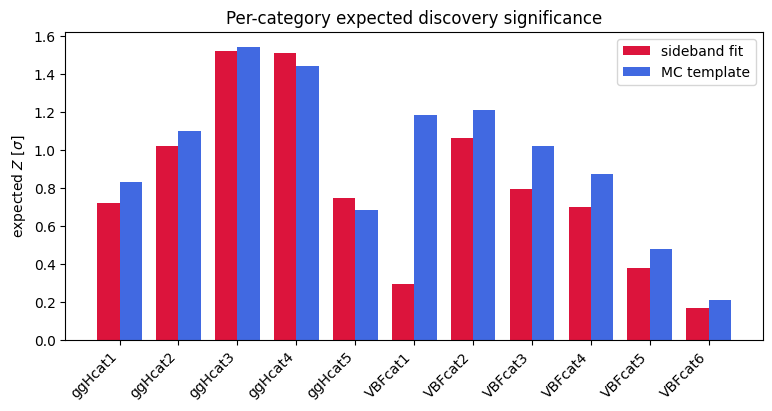

In [18]:
# (d) Per-category significance bar chart
plotting.plot_significance_bars(rows_sb, rows_mc); plt.show()

## Summary

* pyhf gives an **independent binned cross-check** of the H&rarr;&mu;&mu; expected
  significance directly from the split tuples.
* The **sideband-fit background (model A)** is the right comparison to Combine;
  the MC-template result brackets it from above.
* Everything is driven from `python/fits/` modules &mdash; re-run headless with
  `python -m python.fits.run_pyhf_fits --channels all --background both`.

### Known limitations / next steps
* No discrete profiling &mdash; approximated by the background-family envelope (Step 3).
* Signal systematics are flat placeholders &mdash; wire in the real per-event
  systematic weights (needs `scripts/split_tuples.py` to carry them).
* Per-event mass-resolution categories not possible (`relative_diMuon_bsConstrainedMass_error`
  is not in the split trees).
* Low-stats VBF categories (VBFcat1&ndash;2) have poorly constrained sideband fits.